## Installing all libaries needed for the project

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet

warnings.filterwarnings('ignore')
os.makedirs('output', exist_ok=True)
np.random.seed(42)
print('Libraries loaded successfully')

Libraries loaded successfully


## Simulating demand data of three years of weekly order volume. Added seasonality and noise to make the simulation more realistic

In [2]:
weeks = pd.date_range(start='2022-01-03', periods=156, freq='W')

base_demand    = 5000
growth_rate    = 0.004
seasonal_amp   = 0.20
noise_std      = 0.07

sales = []
for i, week in enumerate(weeks):
    trend    = base_demand * (1 + growth_rate * i)
    seasonal = 1 + seasonal_amp * np.sin(2 * np.pi * (week.dayofyear - 80) / 365)
    noise    = np.random.normal(1.0, noise_std)
    sales.append(max(0, round(trend * seasonal * noise, 2)))

df_weekly = pd.DataFrame({'ds': weeks, 'y': sales})

print(f'Weeks generated : {len(df_weekly)}')
print(f'Date range      : {df_weekly["ds"].min().date()} to {df_weekly["ds"].max().date()}')
print(f'Avg weekly sales: ${df_weekly["y"].mean():,.0f}')
df_weekly.head()

Weeks generated : 156
Date range      : 2022-01-09 to 2024-12-29
Avg weekly sales: $6,509


,ds,y
0,2022-01-09,4201.32
1,2022-01-16,4084.53
2,2022-01-23,4392.70
3,2022-01-30,4750.24
4,2022-02-06,4322.73


## Train/Test split into 12 week sets

In [3]:
SPLIT    = len(df_weekly) - 12
train_df = df_weekly.iloc[:SPLIT].copy()
test_df  = df_weekly.iloc[SPLIT:].copy()
actual   = test_df['y'].values

print(f'Training weeks : {SPLIT}')
print(f'Test weeks     : 12')
print(f'Split date     : {test_df["ds"].iloc[0].date()}')

Training weeks : 144
Test weeks     : 12
Split date     : 2024-10-13


## ARIMA model

In [4]:
print('Fitting ARIMA(2,1,2)...')
arima_fit   = ARIMA(train_df['y'].values, order=(2, 1, 2)).fit()
arima_preds = np.maximum(arima_fit.forecast(steps=12), 0)

arima_mape = float(np.mean(np.abs((actual - arima_preds) / actual)) * 100)
print(f'ARIMA MAPE: {arima_mape:.2f}%')

Fitting ARIMA(2,1,2)...
ARIMA MAPE: 12.12%


## Prophet model

In [5]:
print('Fitting Prophet...')
m = Prophet(yearly_seasonality=True, weekly_seasonality=False,
            daily_seasonality=False, interval_width=0.95)
m.fit(train_df)

future        = m.make_future_dataframe(periods=12, freq='W')
prophet_preds = np.maximum(m.predict(future).iloc[-12:]['yhat'].values, 0)

prophet_mape = float(np.mean(np.abs((actual - prophet_preds) / actual)) * 100)
print(f'Prophet MAPE: {prophet_mape:.2f}%')

18:01:50 - cmdstanpy - INFO - Chain [1] start processing
18:01:50 - cmdstanpy - INFO - Chain [1] done processing


Fitting Prophet...
Prophet MAPE: 5.18%


## Comparing the two models

In [6]:
best = 'ARIMA' if arima_mape < prophet_mape else 'Prophet'

summary = pd.DataFrame({
    'Model'                : ['ARIMA', 'Prophet'],
    'MAPE (%)'             : [round(arima_mape, 2), round(prophet_mape, 2)],
    'Avg Weekly Error ($)' : [
        round(np.mean(np.abs(actual - arima_preds)), 0),
        round(np.mean(np.abs(actual - prophet_preds)), 0)
    ]
})
print(summary.to_string(index=False))
print(f'\nBetter performing model: {best}')

  Model  MAPE (%)  Avg Weekly Error ($)
  ARIMA     12.12                 783.0
Prophet      5.18                 331.0

Better performing model: Prophet


## Visualizing the results

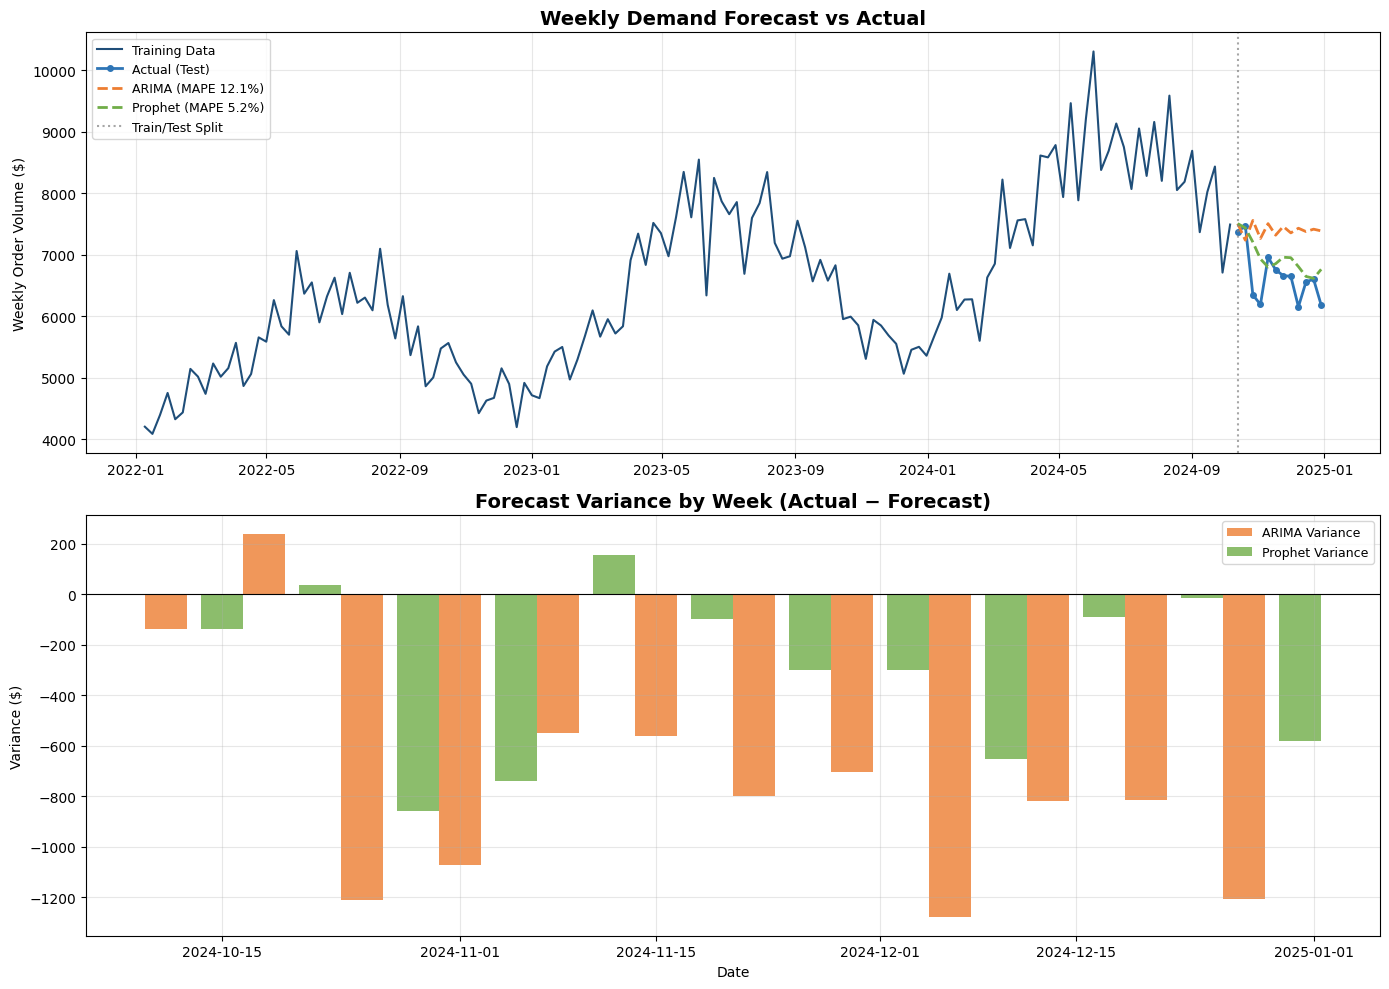

Saved → output/forecast_chart.png


In [7]:
arima_var   = actual - arima_preds
prophet_var = actual - prophet_preds

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

ax1.plot(train_df['ds'], train_df['y'],
         color='#1f4e79', linewidth=1.5, label='Training Data')
ax1.plot(test_df['ds'], actual,
         color='#2e75b6', linewidth=2, marker='o', markersize=4, label='Actual (Test)')
ax1.plot(test_df['ds'], arima_preds,
         color='#ed7d31', linewidth=2, linestyle='--',
         label=f'ARIMA (MAPE {arima_mape:.1f}%)')
ax1.plot(test_df['ds'], prophet_preds,
         color='#70ad47', linewidth=2, linestyle='--',
         label=f'Prophet (MAPE {prophet_mape:.1f}%)')
ax1.axvline(test_df['ds'].iloc[0], color='gray', linestyle=':', alpha=0.7,
            label='Train/Test Split')
ax1.set_title('Weekly Demand Forecast vs Actual', fontsize=14, fontweight='bold')
ax1.set_ylabel('Weekly Order Volume ($)')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

x  = test_df['ds']
td = pd.Timedelta(days=2)
ax2.bar(x - td, arima_var,   width=3, label='ARIMA Variance',   color='#ed7d31', alpha=0.8)
ax2.bar(x + td, prophet_var, width=3, label='Prophet Variance', color='#70ad47', alpha=0.8)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.set_title('Forecast Variance by Week (Actual − Forecast)', fontsize=14, fontweight='bold')
ax2.set_ylabel('Variance ($)')
ax2.set_xlabel('Date')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('output/forecast_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → output/forecast_chart.png')

## Creating inventory planning recommendations 

In [8]:
pos_var    = arima_var[arima_var > 0]
avg_under  = pos_var.mean() if len(pos_var) > 0 else 0
buffer_pct = round(avg_under / test_df['y'].mean() * 100, 1)

high_var = test_df.copy()
high_var['abs_var'] = np.abs(arima_var)
top3 = high_var.nlargest(3, 'abs_var')['ds'].dt.strftime('%Y-%m-%d').tolist()

print('=== Inventory Planning Recommendations ===')
print(f'\n1. Safety Stock Buffer')
print(f'   ARIMA under-predicted by an avg of ${avg_under:,.0f} in high-demand weeks.')
print(f'   Recommendation: Hold ~{buffer_pct}% safety stock buffer above forecast.')
print(f'\n2. Model Selection')
print(f'   {best} achieved lower MAPE — use as primary forecast with ARIMA as cross-check.')
print(f'\n3. High-Variance Weeks')
print(f'   Highest variance weeks: {top3}')
print(f'   Investigate seasonal patterns or demand spikes during these periods.')

=== Inventory Planning Recommendations ===

1. Safety Stock Buffer
   ARIMA under-predicted by an avg of $237 in high-demand weeks.
   Recommendation: Hold ~3.6% safety stock buffer above forecast.

2. Model Selection
   Prophet achieved lower MAPE — use as primary forecast with ARIMA as cross-check.

3. High-Variance Weeks
   Highest variance weeks: ['2024-12-08', '2024-10-27', '2024-12-29']
   Investigate seasonal patterns or demand spikes during these periods.


## Exporting the results into a Tableau dashboard

In [17]:
out = df_weekly.copy()
out['period'] = 'Train'
out.loc[out.index >= SPLIT, 'period']           = 'Test'
out.loc[out.index >= SPLIT, 'arima_forecast']   = arima_preds
out.loc[out.index >= SPLIT, 'prophet_forecast'] = prophet_preds
out.loc[out.index >= SPLIT, 'arima_variance']   = arima_var
out.loc[out.index >= SPLIT, 'prophet_variance'] = prophet_var

out.to_csv('output/forecast_tableau.csv', index=False)
summary.to_csv('output/model_summary.csv', index=False)

print('Exported:')
print('  output/forecast_tableau.csv')
print('  output/model_summary.csv')
print('  output/forecast_chart.png')
print(f'\nFinal MAPE — ARIMA: {arima_mape:.2f}%  |  Prophet: {prophet_mape:.2f}%')

Exported:
  output/forecast_tableau.csv
  output/model_summary.csv
  output/forecast_chart.png

Final MAPE — ARIMA: 12.12%  |  Prophet: 5.18%
